# Anatomy of Persuasion · M0 baseline

**Prediction time:** 24 hours after a top-level reply opens a branch. **Target:** its first verified OP-awarded delta in the following seven days. The cohort uses all eligible branches, including branches outside the paired dataset.

| Model | Inputs available at hour 24 |
| --- | --- |
| **M0a · Minimal** | Early non-OP comments, opening delay, opening reply word count |
| **M0b · Structural** | M0a plus unique early non-OP authors and maximum early reply depth |

The metadata and text come from the same frozen Parquet releases as the [engagement study](../../nested-replies-analysis/op_engagement_study.ipynb). Early non-OP counts cover identifiable non-OP authors, excluding DeltaBot and AutoModerator. Opening length uses archived text with quoted lines and clearly marked edit sections removed. The archive can retain unmarked edits. Depth is measured from the opening at depth 0 and can reflect OP participation indirectly. This is why we also fit M0a. Missing feature values are imputed with medians learned on training data.

Run with a kernel that has the project's data package, pandas, NumPy, scikit-learn, and Matplotlib. Missing feature tables are rebuilt automatically.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display


REPO = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "team-setup").is_dir() and (path / "pyproject.toml").is_file()
)
MODEL_DIR = REPO / "project/notebooks/models/M0-baseline"
DATA = REPO / "project/data/processed/m0-baseline"
BUILDER = (
    REPO / "project/notebooks/nested-replies-analysis/op_engagement_study/build_branch_dataset.py"
)
FEATURES = {
    "M0a": ["non_op_comments_24h", "opening_delay_minutes", "opening_reply_length"],
    "M0b": [
        "non_op_comments_24h", "opening_delay_minutes", "opening_reply_length",
        "unique_non_op_authors_24h", "max_depth_24h",
    ],
}
TARGET = "delta_after_24h"
datasets = {}
audits = {}
for split in ("train", "heldout"):
    split_dir = DATA / split
    if not all((split_dir / name).is_file() for name in ("branches.parquet", "audit.json")):
        subprocess.run(
            [sys.executable, str(BUILDER), "--split", split, "--model-features"], check=True,
        )
    audits[split] = json.loads((split_dir / "audit.json").read_text())
    rows = pd.read_parquet(split_dir / "branches.parquet")
    datasets[split] = rows.loc[rows["eligible"]].sort_values("branch_id").reset_index(drop=True)
    datasets[split][TARGET] = datasets[split][TARGET].astype(int)

train, heldout = datasets["train"], datasets["heldout"]
assert set(train["post_id"]).isdisjoint(heldout["post_id"])
display(pd.DataFrame({
    split: {
        "eligible branches": len(data),
        "discussions": data["post_id"].nunique(),
        "later deltas": data[TARGET].sum(),
        "delta prevalence": data[TARGET].mean(),
        "missing opening lengths": data["opening_reply_length"].isna().sum(),
        "missing opening delays": data["opening_delay_minutes"].isna().sum(),
    }
    for split, data in datasets.items()
}).T)
display(pd.DataFrame({
    split: {
        "award and confirmation cross cutoff": audit["exclusions"].get("award_and_confirmation_cross_cutoff", 0),
        "published positive branches": audit["counts"]["published_positive_openings"],
        "published positives with verified awards": audit["counts"]["published_positive_openings_with_verified_award"],
    }
    for split, audit in audits.items()
}).T)

,eligible branches,discussions,later deltas,delta prevalence,missing opening lengths,missing opening delays
train,207564.0,17981.0,404.0,0.001946,9244.0,0.0
heldout,24301.0,2088.0,22.0,0.000905,1022.0,0.0


,award and confirmation cross cutoff,published positive branches,published positives with verified awards
train,258,3438,3438
heldout,652,802,802


## Choose regularization using the training split

Both baselines use L2-regularized logistic regression with the original class frequencies. Inside each fit, fill missing values, apply `log1p`, and standardize the features. Select regularization by mean average precision across three validation folds, grouping by `post_id` so that all branches of a discussion stay together. Refit on the full training cohort after selection. The published held-out split is used for evaluation.

[scikit-learn average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


SEED = 42
splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(splitter.split(train, train[TARGET], groups=train["post_id"]))
for fit_rows, validation_rows in folds:
    assert set(train.iloc[fit_rows]["post_id"]).isdisjoint(train.iloc[validation_rows]["post_id"])
    assert train.iloc[validation_rows][TARGET].nunique() == 2

models = {}
selection = []
coefficient_rows = []
for name, columns in FEATURES.items():
    baseline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(solver="lbfgs", max_iter=1000)),
    ])
    search = GridSearchCV(
        baseline, {"logistic__C": [0.01, 0.1, 1, 10]},
        scoring="average_precision", cv=folds, refit=True, error_score="raise",
    )
    search.fit(train[columns], train[TARGET])
    models[name] = search.best_estimator_
    selection.append({
        "model": name, "C": search.best_params_["logistic__C"],
        "mean validation average precision": search.best_score_,
    })
    coefficients = models[name].named_steps["logistic"].coef_[0]
    coefficient_rows.extend(
        {"model": name, "feature": feature, "log-odds per standardized unit": coefficient}
        for feature, coefficient in zip(columns, coefficients)
    )

display(pd.DataFrame(selection).set_index("model").round(6))
display(pd.DataFrame(coefficient_rows).set_index(["model", "feature"]).round(3))

,C,mean validation average precision
model,,
M0a,10,0.005481
M0b,10,0.005524


log-odds per standardized unit
model feature                                                  
M0a   non_op_comments_24h                                 0.161
      opening_delay_minutes                              -0.339
      opening_reply_length                                0.605
M0b   non_op_comments_24h                                -0.034
      opening_delay_minutes                              -0.288
      opening_reply_length                                0.618
      unique_non_op_authors_24h                          -0.040
      max_depth_24h                                       0.293

## Evaluate once on held-out discussions

Average precision summarizes the precision–recall curve. Held-out prevalence is the reference for a constant ranking. For Brier score, the constant model predicts training prevalence for every held-out branch. Precision and recall at 100 describe a shortlist of the 100 highest-scored branches. Ties in the shortlist are resolved by branch ID. To check calibration, compare the mean predicted probability with the observed rate in five equally sized rank groups. With few positives, small differences in these metrics are uncertain. Average-precision intervals use 500 paired bootstrap draws of whole held-out discussions.

In [3]:
y = heldout[TARGET].to_numpy()
prevalence = float(y.mean())
k = min(100, len(heldout))
results = []
calibration_rows = []
predictions = heldout[["post_id", "branch_id", TARGET]].copy()
for name, columns in FEATURES.items():
    probability = models[name].predict_proba(heldout[columns])[:, 1]
    predictions[name] = probability
    # Held-out rows are already sorted by branch ID to give ties a stable order.
    top = np.argsort(-probability, kind="stable")[:k]
    results.append({
        "model": name,
        "average precision": average_precision_score(y, probability),
        "ROC-AUC": roc_auc_score(y, probability),
        "Brier score": brier_score_loss(y, probability),
        "precision@100": float(y[top].mean()),
        "recall@100": float(y[top].sum() / y.sum()),
        "deltas in top 100": int(y[top].sum()),
    })
    # Use equally sized probability groups so the diagnostic has similar support per point.
    for bin_id, members in enumerate(np.array_split(np.argsort(probability, kind="stable"), 5), start=1):
        calibration_rows.append({
            "model": name, "bin": bin_id, "branches": len(members), "deltas": int(y[members].sum()),
            "mean predicted probability": float(probability[members].mean()),
            "observed delta rate": float(y[members].mean()),
        })
results = pd.DataFrame(results).set_index("model")
calibration = pd.DataFrame(calibration_rows).set_index(["model", "bin"])
display(results.round(6))
display(calibration.round(6))
print(f"Held-out prevalence / constant-ranking AP: {prevalence:.6f}")
print(f"Constant-probability Brier score: {brier_score_loss(y, np.full(len(y), train[TARGET].mean())):.6f}")
predictions.to_parquet(DATA / "heldout_predictions.parquet", index=False)

,average precision,ROC-AUC,Brier score,precision@100,recall@100,deltas in top 100
model,,,,,,
M0a,0.001517,0.650864,0.000907,0.0,0.0,0
M0b,0.001489,0.663439,0.000907,0.0,0.0,0


branches  deltas  mean predicted probability  observed delta rate
model bin                                                                   
M0a   1        4861       0                    0.000585             0.000000
      2        4860       4                    0.001113             0.000823
      3        4860       6                    0.001647             0.001235
      4        4860       5                    0.002381             0.001029
      5        4860       7                    0.004252             0.001440
M0b   1        4861       0                    0.000560             0.000000
      2        4860       3                    0.001084             0.000617
      3        4860       3                    0.001616             0.000617
      4        4860      10                    0.002374             0.002058
      5        4860       6                    0.004283             0.001235

Held-out prevalence / constant-ranking AP: 0.000905
Constant-probability Brier score: 0.000906


In [4]:
# Use the same held-out discussion draws for both models to estimate the AP gap.
post_codes, post_ids = pd.factorize(heldout["post_id"])
bootstrap_rng = np.random.default_rng(SEED)
bootstrap_ap = []
for draw in bootstrap_rng.multinomial(len(post_ids), np.full(len(post_ids), 1 / len(post_ids)), size=500):
    sample_weights = draw[post_codes]
    if np.dot(sample_weights, y) == 0:
        continue
    bootstrap_ap.append([
        average_precision_score(y, predictions[name], sample_weight=sample_weights) for name in FEATURES
    ])
bootstrap_ap = np.asarray(bootstrap_ap)
bootstrap_gap = bootstrap_ap[:, 1] - bootstrap_ap[:, 0]
intervals = np.quantile(np.column_stack([bootstrap_ap, bootstrap_gap]), [0.025, 0.975], axis=0)
display(pd.DataFrame({
    "estimate": [
        *results["average precision"],
        results.at["M0b", "average precision"] - results.at["M0a", "average precision"],
    ],
    "95% CI lower": intervals[0], "95% CI upper": intervals[1],
}, index=["M0a AP", "M0b AP", "M0b minus M0a AP"]).round(6))

,estimate,95% CI lower,95% CI upper
M0a AP,0.001517,0.000865,0.002718
M0b AP,0.001489,0.000915,0.002765
M0b minus M0a AP,-0.000028,-0.000505,0.000510


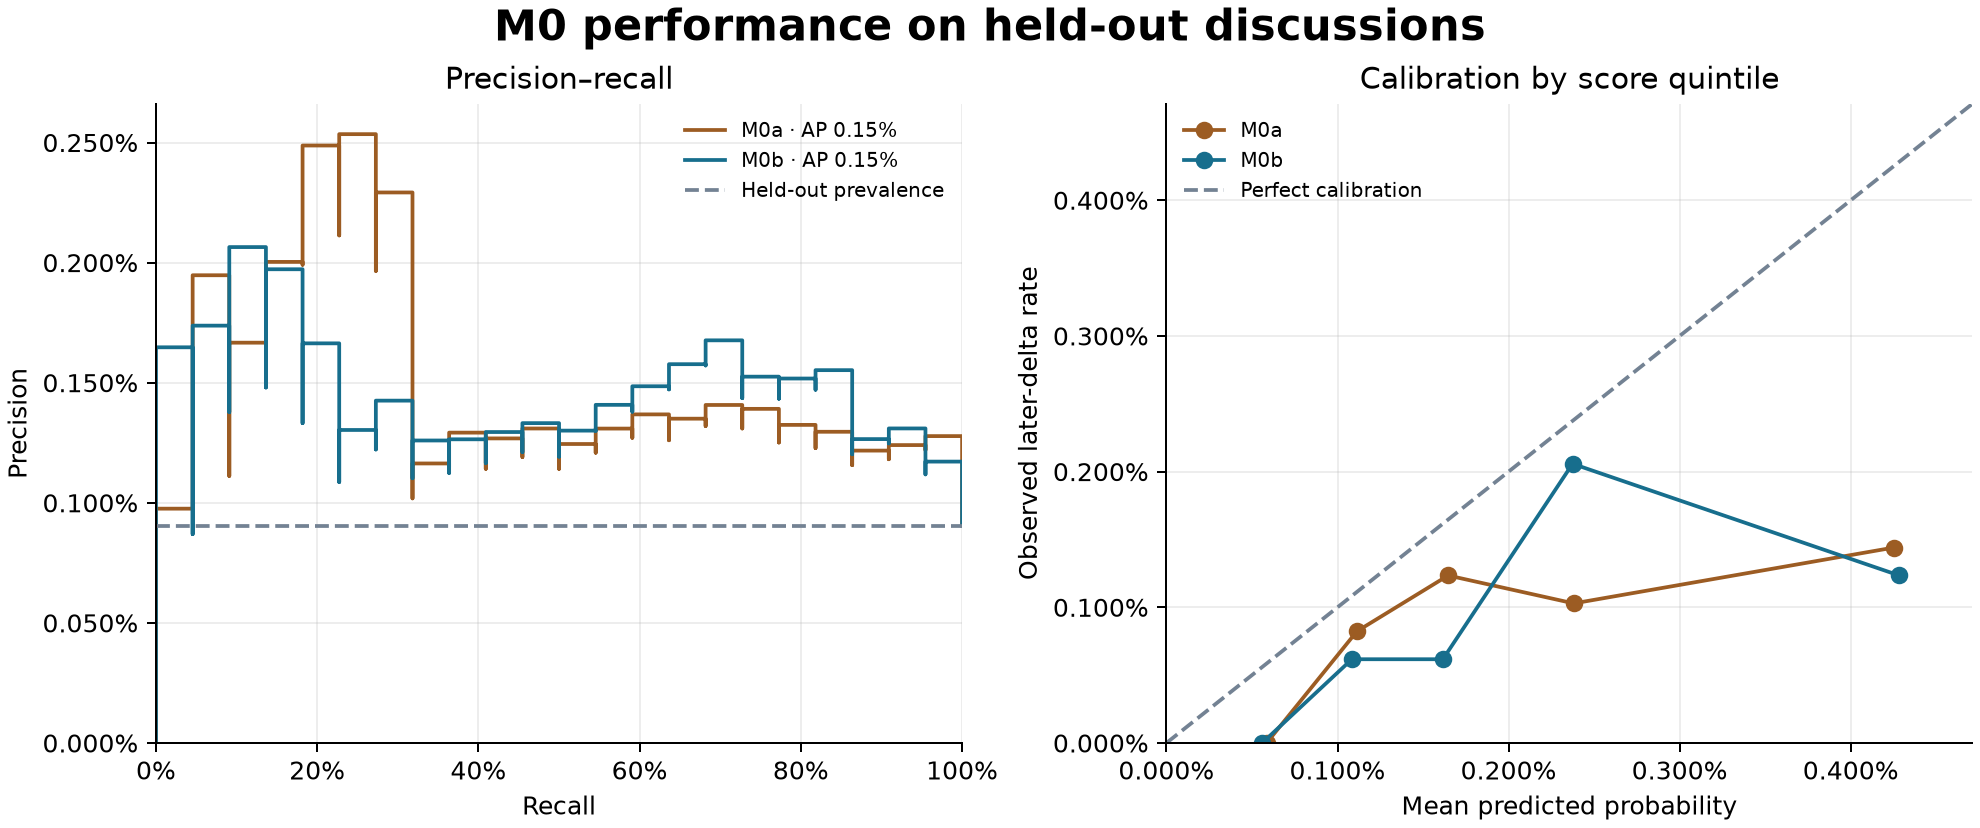

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


colors = {"M0a": "#9c5c23", "M0b": "#176e8d"}
fig, (pr, cal) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
fig.suptitle("M0 performance on held-out discussions", fontsize=17, weight="bold")
for name, color in colors.items():
    precision, recall, _ = precision_recall_curve(y, predictions[name])
    # The final PR endpoint has recall zero and precision one by convention.
    pr.step(recall[:-1], 100 * precision[:-1], where="post", color=color,
            label=f"{name} · AP {results.at[name, 'average precision']:.2%}")
    curve = calibration.loc[name]
    cal.plot(100 * curve["mean predicted probability"], 100 * curve["observed delta rate"],
             "o-", color=color, label=name)
pr.axhline(100 * prevalence, color="#738293", linestyle="--", label="Held-out prevalence")
pr.set(xlim=(0, 1), ylim=(0, None), title="Precision–recall", xlabel="Recall", ylabel="Precision")
pr.xaxis.set_major_formatter(PercentFormatter(1))
pr.yaxis.set_major_formatter(PercentFormatter(100))
limit = 1.1 * 100 * calibration[["mean predicted probability", "observed delta rate"]].max().max()
cal.plot([0, limit], [0, limit], color="#738293", linestyle="--", label="Perfect calibration")
cal.set(xlim=(0, limit), ylim=(0, limit), title="Calibration by score quintile",
        xlabel="Mean predicted probability", ylabel="Observed later-delta rate")
cal.xaxis.set_major_formatter(PercentFormatter(100))
cal.yaxis.set_major_formatter(PercentFormatter(100))
for ax in (pr, cal):
    ax.grid(alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.savefig(MODEL_DIR / "m0_heldout_performance.png", dpi=180, facecolor="white")
plt.show()